In [1]:
title = "# Introduction to Bayesian statistics: exercises"
# Print title and setup TeX defs for both KaTeX and MathJax
import bayesian_stats_course_tools
bayesian_stats_course_tools.misc.display_markdown_and_setup_tex(title)
import numpy as np
import matplotlib.style
matplotlib.style.use("bayesian_stats_course_tools.light")

import matplotlib.pyplot as plt

# Introduction to Bayesian statistics: exercises

<!-- Define LaTeX macros -->
$\def\E{\operatorname{E}}$
$\def\Var{\operatorname{Var}}$
$\def\Cov{\operatorname{Cov}}$
$\def\dd{\mathrm{d}}$
$\def\ee{\mathrm{e}}$
$\def\Norm{\mathcal{N}}$
$\def\Uniform{\mathcal{U}}$
$\def\GP{\mathcal{GP}}$

<!-- MathJax needs them to be defined again for the non-inline environment -->
$$\def\E{\operatorname{E}}$$
$$\def\Var{\operatorname{Var}}$$
$$\def\Cov{\operatorname{Cov}}$$
$$\def\dd{\mathrm{d}}$$
$$\def\ee{\mathrm{e}}$$
$$\def\Norm{\mathcal{N}}$$
$$\def\Uniform{\mathcal{U}}$$
$$\def\GP{\mathcal{GP}}$$

# Exercise 1

- Implement your own version of the line-fitting procedure, using the same data.
- Now try it with the data in `lectures/data/linear_fits/data_1.txt`
    - First plot the data. What has changed?
    - Try the same model and likelihood on the new data. You might want to adjust the prior on $m$ and $b$ for this new data set.
    - What if you use the provided uncertainty per data point $\sigma_{y_i}$, instead of assuming a constant variance $\sigma_y$ for all data points?
    - Instead use the actual likelihood of the data:
\begin{align}
    \mu(x) &= mx + b \\
    \sigma(x_i) &= \sigma_{y_i} + f\mu(x_i)^2 \quad f > 0\ \text{a parameter} \\
    y_i&\sim\mathcal N(\mu(x_i),\sigma(x_i)^2)
\end{align}
Careful with the normalisation of the Gaussian likelihood. Because we vary the variance, this matters now!

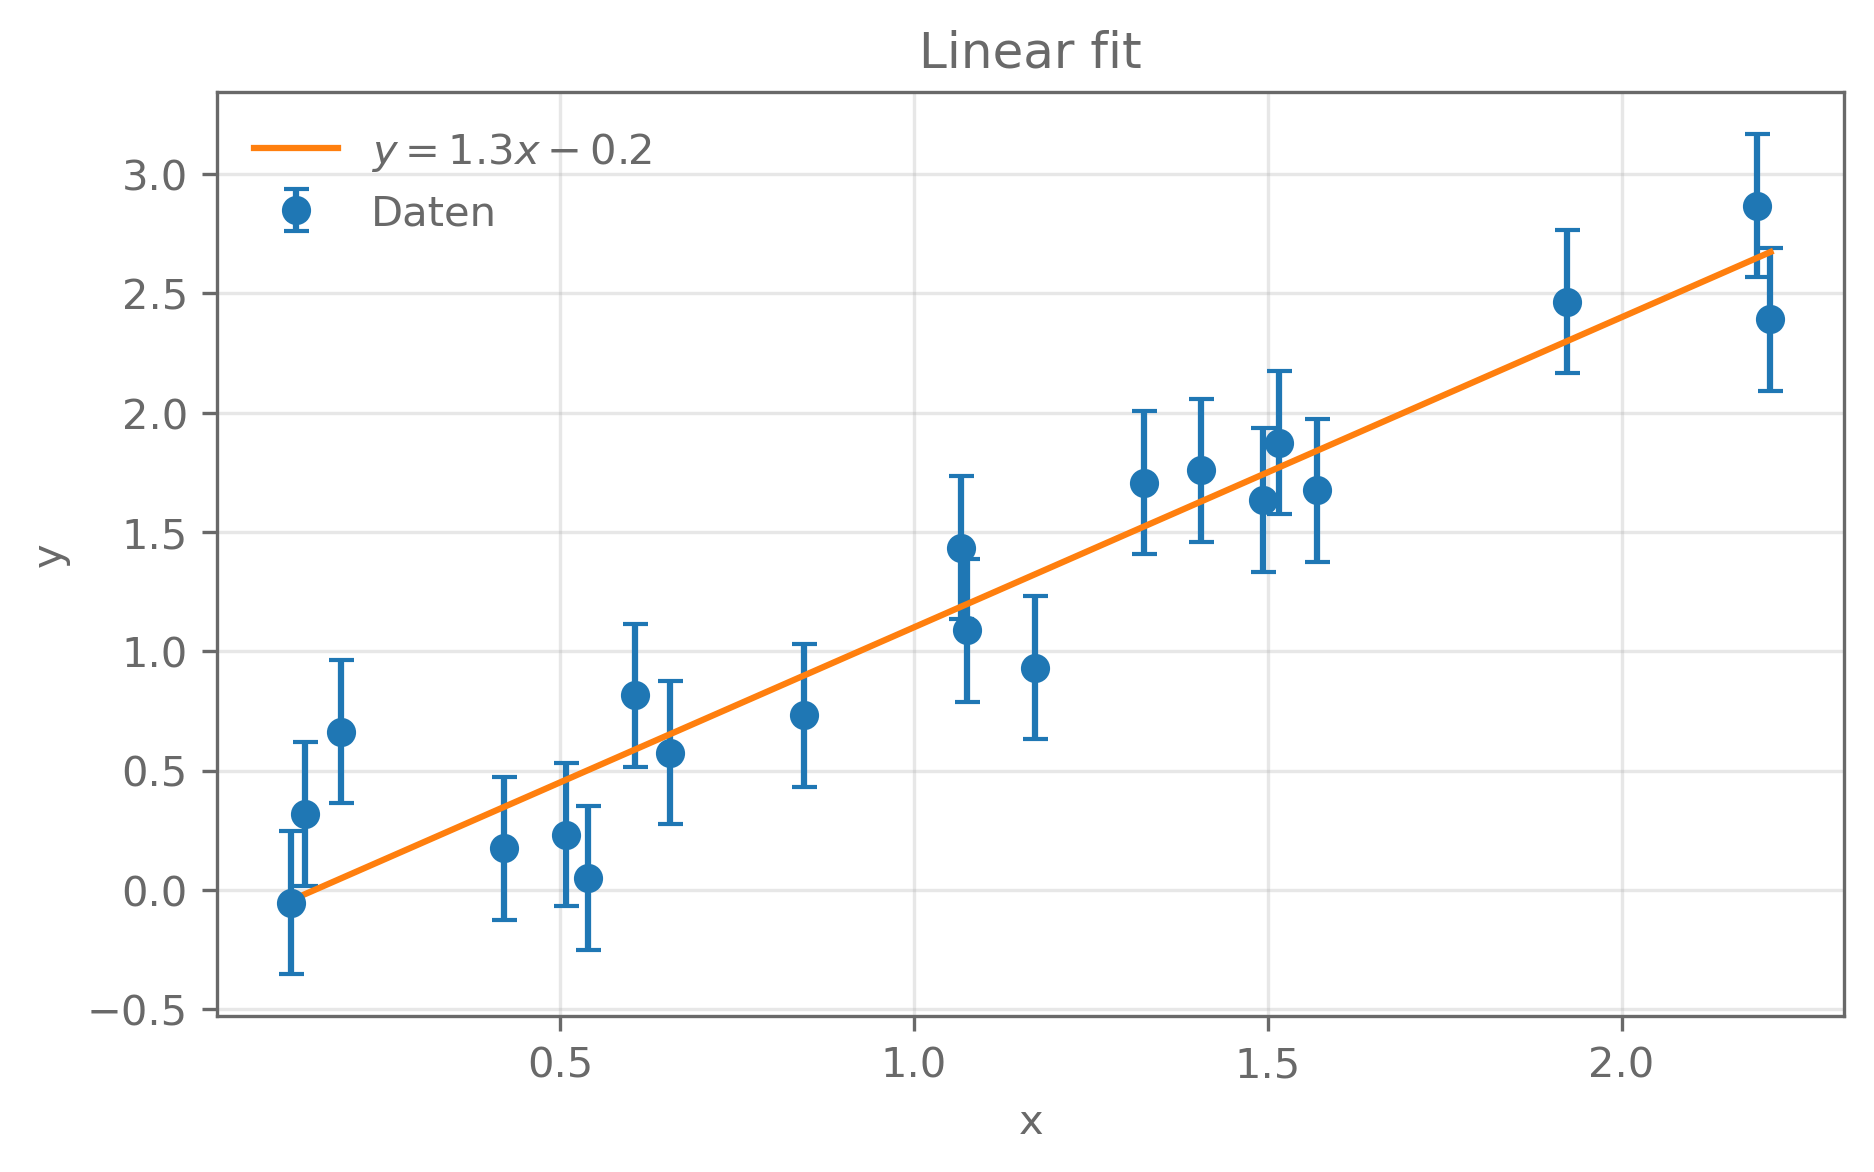

In [2]:
# load data
x, y, yerr = np.loadtxt(
    "../lectures/data/linear_fits/data_0.txt",
    unpack=True
)

# true values
m = 1.3
b = -0.2

x_line = np.linspace(x.min(), x.max(), 100)

y_line = m * x_line + b

# plot with errorbars
plt.errorbar(
    x,
    y,
    yerr=yerr,
    fmt="o",
    capsize=3,
    label="Daten"
)

# true straight
plt.plot(
    x_line,
    y_line,
    label=r"$y = 1.3x -0.2$" #m=1.3, b=-0.2
)

# label
plt.xlabel("x")
plt.ylabel("y")
plt.title("Linear fit")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

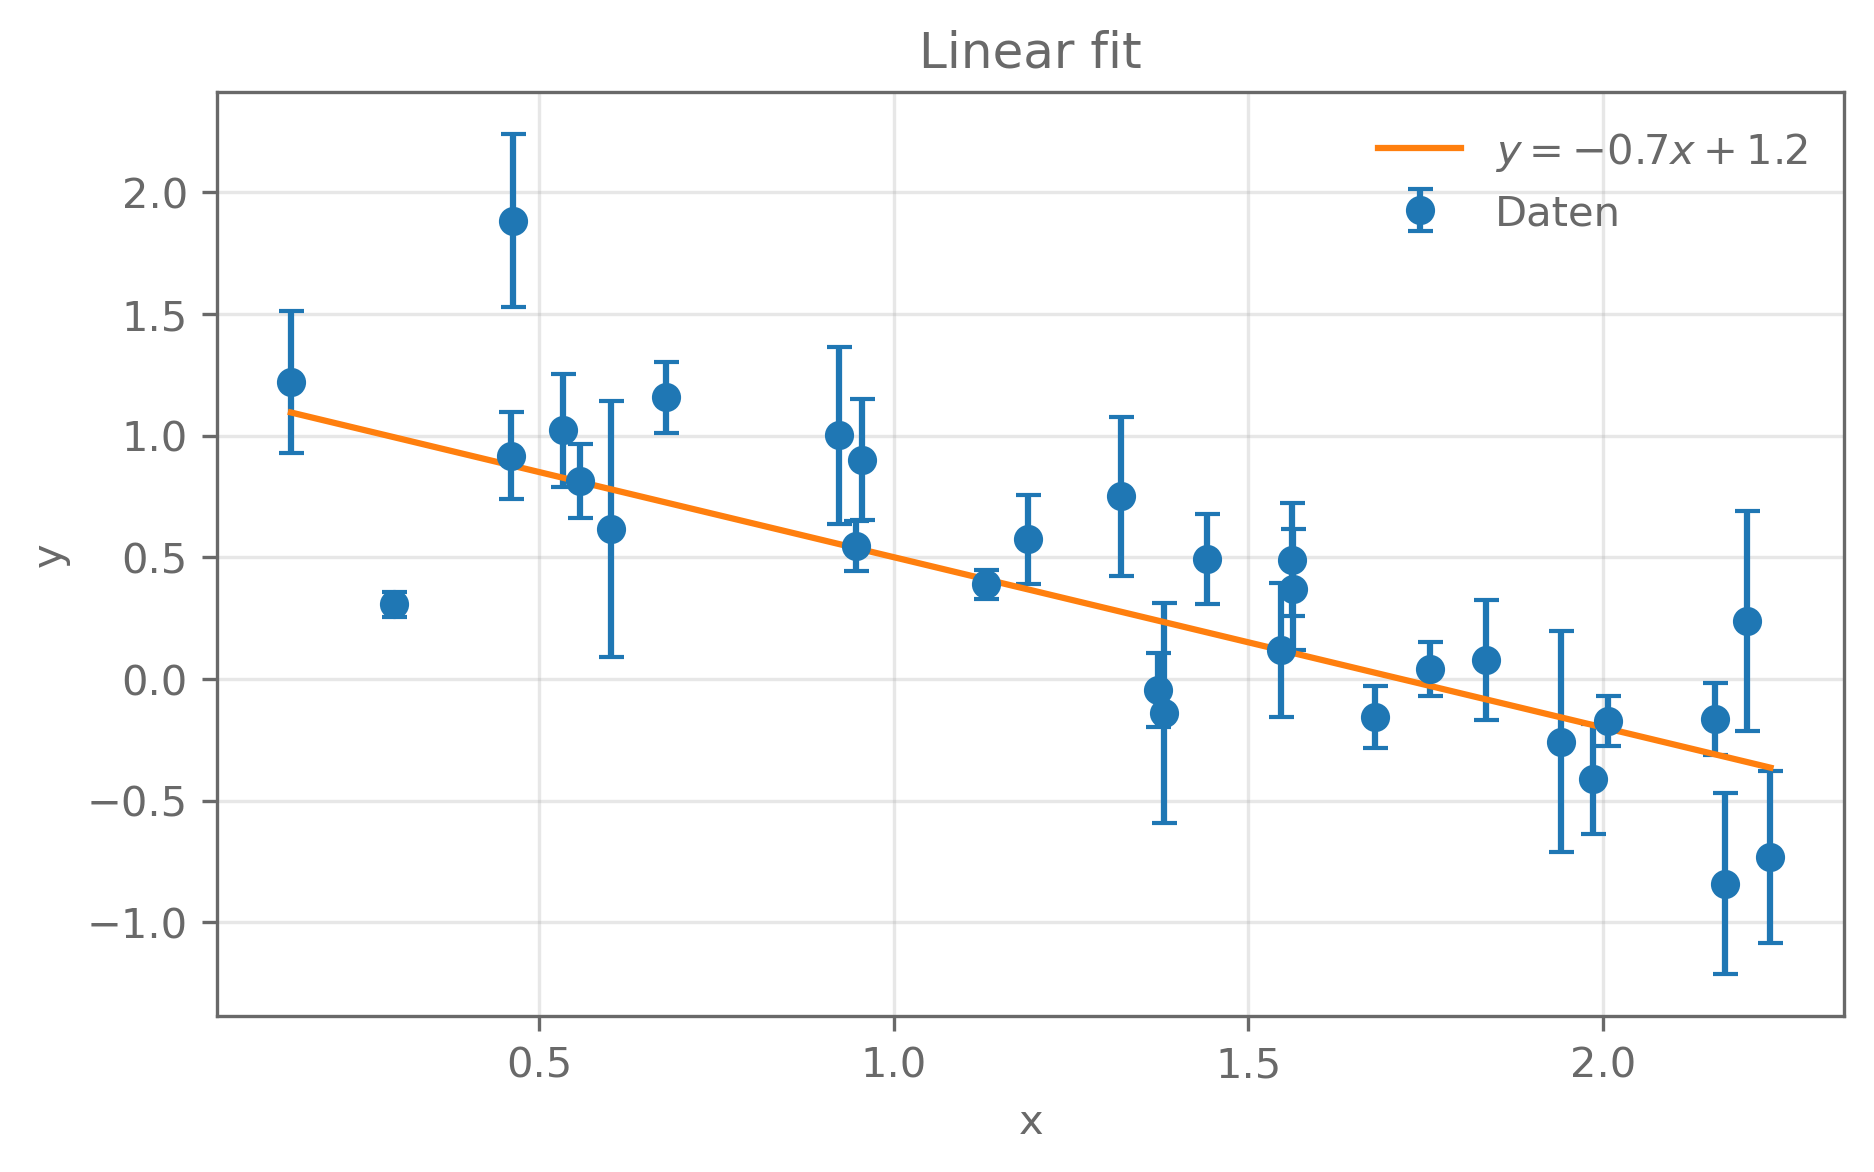

In [3]:
# load data
x, y, yerr = np.loadtxt(
    "../lectures/data/linear_fits/data_1.txt",
    unpack=True
)

# true values
m = -0.7
b = 1.2

x_line = np.linspace(x.min(), x.max(), 100)

y_line = m * x_line + b

# plot with errorbars
plt.errorbar(
    x,
    y,
    yerr=yerr,
    fmt="o",
    capsize=3,
    label="Daten"
)

# true straight
plt.plot(
    x_line,
    y_line,
    label=r"$y = -0.7x + 1.2$"
)

# label
plt.xlabel("x")
plt.ylabel("y")
plt.title("Linear fit")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

#### Change: Non-cosntant errorbars

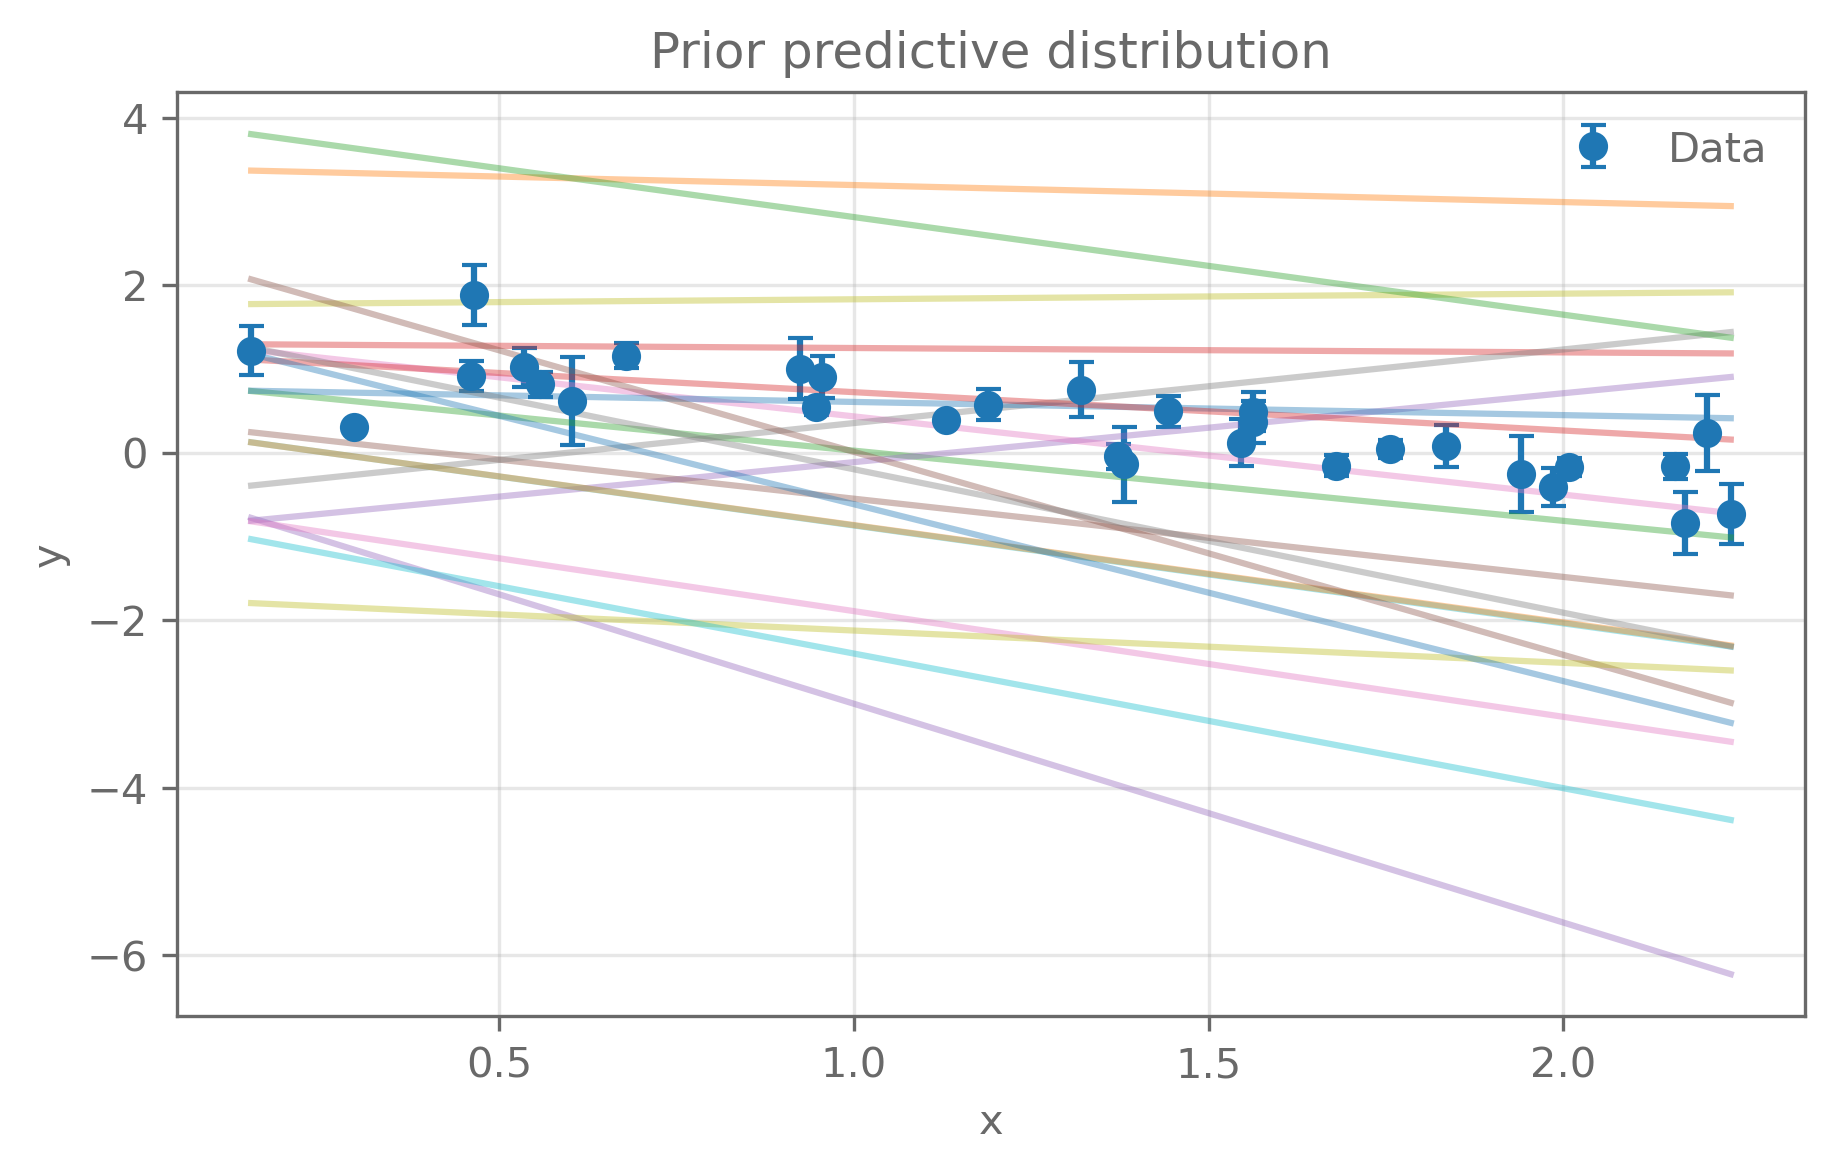

In [5]:
import scipy as scipy

# Load data
x, y, yerr = np.loadtxt(
    "../lectures/data/linear_fits/data_1.txt",
    unpack=True
)

# The linear model
def model(m, b, x):
    return m*x + b

# Probability of the data, given the model parameters
def log_likelihood_probability(y, m, b, x, sigma_y):
    prediction = model(m, b, x)

    n = len(y)

    return (
        -0.5 * np.sum((y - prediction)**2/sigma_y**2)
        - n/2*np.log(2*np.pi*sigma_y**2)
    )

# Priors
m_prior = scipy.stats.norm(loc=-0.7, scale=1)
b_prior = scipy.stats.norm(loc=1.2, scale=1.5)

def log_prior_probability(m, b):
    return m_prior.logpdf(m) + b_prior.logpdf(b)


def sample_prior(n_sample):
    """Sample n_sample times from the prior distribution."""
    return np.vstack((m_prior.rvs(n_sample), b_prior.rvs(n_sample))).T


# Fix the pseudo random number generator seed for reproducibility
np.random.seed(42)

# Evaluate the model at the prior sample parameters
prior_model_predictive = np.array(
    [model(*parameters, x) for parameters in sample_prior(n_sample=20)]
)

# Plot data and prior predictions
plt.errorbar(
    x, y, yerr=yerr,
    fmt="o",
    capsize=3,
    label="Data"
)

for prediction in prior_model_predictive:
    plt.plot(x, prediction, alpha=0.4)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Prior predictive distribution")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Load data
x, y, yerr = np.loadtxt(
    "../lectures/data/linear_fits/data_1.txt",
    unpack=True
)

# Linear model
def model(m, b, x):
    return m*x + b

# Priors
m_prior = norm(loc=-0.7, scale=1)
b_prior = norm(loc=1.2, scale=1.5)

def sample_prior(n_sample):
    """Sample n_sample times from the prior distribution."""
    return np.vstack((m_prior.rvs(n_sample), b_prior.rvs(n_sample))).T

# Fix the random seed
np.random.seed(42)

# Evaluate the model at the prior sample parameters
prior_model_predictive = np.array(
    [model(*parameters, x) for parameters in sample_prior(n_sample=20)]
)

# Plot
plt.errorbar(x, y, yerr=yerr, fmt="o", capsize=3, label="Data")

for prediction in prior_model_predictive:
    plt.plot(x, prediction, alpha=0.4)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Prior predictive distribution")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Load data
x, y, yerr = np.loadtxt(
    "../lectures/data/linear_fits/data_1.txt",
    unpack=True
)

# Linear model
def model(m, b, x):
    return m*x + b

# Log-likelihood with individual uncertainties
def log_likelihood_probability(y, m, b, x, sigma_y):
    prediction = model(m, b, x)

    return (
        -0.5 * np.sum((y - prediction)**2 / sigma_y**2)
        - 0.5 * np.sum(np.log(2 * np.pi * sigma_y**2))
    )

# Priors
m_prior = norm(loc=-0.7, scale=1)
b_prior = norm(loc=1.2, scale=1.5)

def sample_prior(n_sample):
    """Sample n_sample times from the prior distribution."""
    return np.vstack((m_prior.rvs(n_sample), b_prior.rvs(n_sample))).T

# Fix the random seed
np.random.seed(42)

# Sample prior parameters
parameters = sample_prior(n_sample=20)

# Evaluate the likelihood
log_likelihoods = np.array([
    log_likelihood_probability(y, m, b, x, yerr)
    for m, b in parameters
])

# Best model
best_parameters = parameters[np.argmax(log_likelihoods)]
m_best, b_best = best_parameters

# Plot
x_line = np.linspace(x.min(), x.max(), 100)

plt.errorbar(
    x, y, yerr=yerr,
    fmt="o",
    capsize=3,
    label="Data"
)

plt.plot(
    x_line,
    model(m_best, b_best, x_line),
    label="Best model"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Linear fit with individual uncertainties")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Exercise 2

The data in the previous example were a synthetic version of real observations that were obtained in an AstroWoche project in 2024 by Jonas Spiller, Theo Lequy, Clara Bleich. 

<!-- ![jovian moons data](../assets/jovian_moons_raw_data.png) -->
<img style="display: block; 
    margin-left: auto;
    margin-right: auto;
    width: 60%;"
    src="../assets/jovian_moons_raw_data.png" alt="jovian moons data"/>

The real observations can be found in `data/jovian_moons/{moon}.dat`:

In [6]:
moon = "Io"

t, distance, distance_alt, distance_err = np.loadtxt(
    f"../lectures/data/jovian_moons/{moon}.dat", unpack=True)

1. Repeat the analysis with the real data set. What do you find?

There is another distance estimate provided. The difference between the distance estimates comes from different approaches to converting the measured distance between Jupiter and its moons from the number of pixels to a physical distance in km.

2. How does the analysis look when using this other distance estimate (what I call `distance_alt`)? What about the other moons?



Because there are two distance estimates that do not agree, both of which are based on reasonable approaches, this suggests that there might be a _systematic_ error in the measurements. Systematic errors are usually not random (which means they do not get smaller as you obtain more data). But we could pretend the offset between the two measurements is an estimate of an unaccounted statistical uncertainty. 

3. How does the analysis look when we assume `sigma_d**2 = distance_err**2 + (distance - distance_alt)**2`?



4. Instead of assuming that the uncertainty is underestimated by this offset, we can also model it. Does the model work better if the variance is a free parameter?
